In [5]:
# GLOBAL CONFIG CELL

PATH_TRAINING_DATA = '/home/madhav/workstation/Lab/experiment/data/MLP-PROJECT-DATASET/train.csv'
PATH_TESTING_DATA = '/home/madhav/workstation/Lab/experiment/data/MLP-PROJECT-DATASET/test.csv'

In [6]:
# UTILITY FUNCTIONS
def extract_date(date: str):
    year, month, days = tuple(date.split('-'))
    return (int(year) * (12 * 30)) + (int(month) * 30) + int(days)

def extract_timeline(start_date: str, end_date: str):
    start = extract_date(start_date)
    end = extract_date(end_date)
    timeline = end - start
    if timeline < 0:
        # Fixed typo: 'exception' needs to be capitalized as 'Exception'
        raise Exception(f"timeline dataset is corrupted: start date: {start_date}, end date: {end_date}")
    return timeline

In [7]:
# Loading dataset
import pandas as pd

train_df = pd.read_csv(PATH_TRAINING_DATA)
test_df = pd.read_csv(PATH_TESTING_DATA)

Ploting information : (Index(['borough', 'score_value', 'score_access', 'score_onboarding',
       'score_accuracy', 'score_support'],
      dtype='str'), borough             214451
score_value          54246
score_access         54245
score_onboarding     54243
score_accuracy       54242
score_support        54241
dtype: int64)
Ploting information : (Index(['borough', 'score_onboarding', 'score_access', 'score_value',
       'score_accuracy', 'score_support'],
      dtype='str'), borough             86042
score_onboarding    21459
score_access        21458
score_value         21458
score_accuracy      21456
score_support       21455
dtype: int64)


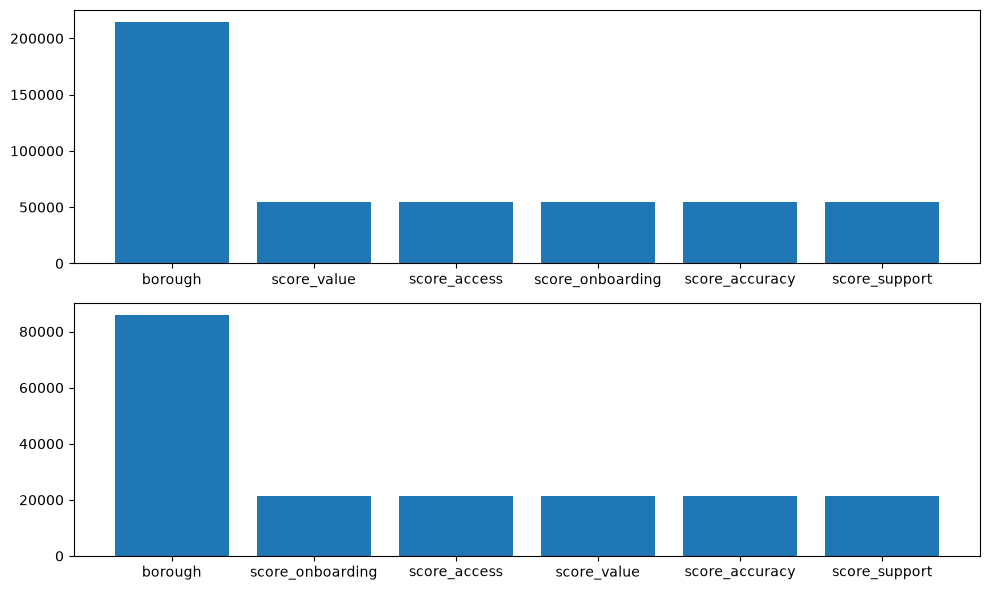

In [8]:
# Null inspection cell
import matplotlib.pyplot as plt

def null_inspection(frames:[pd.DataFrame], chunk=6):
    '''
    INPUT : frames
    OUTPUT : plots values
    order : highest to lowest null values containing columns
    '''
    plots = len(frames)

    plot_info = []
    for frame in frames:
        null_info = frame.isna().sum().sort_values(ascending=False)

        X = null_info.index[:chunk]
        y = null_info[:chunk]

        info_elem = (X,y)
        plot_info.append(info_elem)

    # Ploting Null values
    i = 0
    fig, axs = plt.subplots(plots, 1, figsize=(10,6), layout='tight')
    for ax in axs:
        X,y = plot_info[i]
        print(f"Ploting information : {X, y}")
        ax.bar(X,y)
        i+=1

null_inspection([train_df, test_df])

In [9]:
train_df.columns

Index(['space_id', 'operator_ref', 'operator_platform_age_years',
       'operator_platform_age_months', 'operator_active_years',
       'operator_active_months', 'operator_class', 'operator_certified',
       'operator_portfolio_size', 'operator_has_avatar',
       'operator_id_verified', 'zone', 'borough', 'geo_lat', 'geo_lon',
       'space_class', 'access_type', 'max_seats', 'utility_rooms', 'zones',
       'workstations', 'facilities', 'snapshot_start_date',
       'snapshot_end_date', 'min_term_days', 'max_term_days', 'min_term_floor',
       'min_term_ceiling', 'max_term_floor', 'max_term_ceiling',
       'min_term_avg', 'max_term_avg', 'bookable', 'open_slots_a',
       'open_slots_b', 'open_slots_c', 'open_slots_d', 'review_count',
       'review_count_12m', 'review_count_30d', 'open_slots_e',
       'review_count_prev_yr', 'booked_load', 'first_review_date',
       'last_review_date', 'score_overall', 'score_accuracy',
       'score_condition', 'score_onboarding', 'score_supp

In [10]:
# Feature inspection cell 
from rich import print
import ast
import numpy as np

# Manual Feature Selection for training
selected_features = ['snapshot_end_date',
 'snapshot_start_date',
 'geo_lon',
 'max_seats',
 'access_type',
 'operator_class',
 'zone',
 'geo_lat',
 'space_class',
 'max_term_avg',
 'open_slots_b',
 'open_slots_a',
 'booked_load',
 'review_count_prev_yr',
 'open_slots_e',
 'review_count_30d',
 'review_count',
 'review_count_12m',
 'open_slots_d',
 'open_slots_c',
 'min_term_avg',
 'compliance_status',
 'operator_metro_whole',
 'operator_metro_units',
 'operator_metro_private',
 'operator_metro_shared',
 'metro']

target_feature = 'price_tier'

# Manual sampling based inspection of all features sample set of 30
print(f'Data Insepction sample listing')
for feat in selected_features:
    sample = train_df[feat].sample(n=5)
    print(f"[yellow] Target column : {feat} [/yellow] \n {sample} \n")

Data Insepction sample listing

 Target column : snapshot_end_date  
 262303    2024-08-16
238447    2024-09-02
184545    2024-09-29
17433     2024-08-21
205871    2024-08-23
Name: snapshot_end_date, dtype: str

 Target column : snapshot_start_date  
 18680     2024-08-28
248904    2024-08-15
136263    2025-02-25
76873     2024-08-22
202881    2024-08-18
Name: snapshot_start_date, dtype: str

 Target column : geo_lon  
 188528    -21.2188
256037   -108.3526
241982     47.4212
228485    -31.1014
37564     -31.2262
Name: geo_lon, dtype: float64

 Target column : max_seats  
 116669    2
238604    4
31190     2
260078    2
63668     5
Name: max_seats, dtype: int64

...

 Target column : operator_metro_whole  
 139820    38
99592     20
184170     3
100344     0
24178      8
Name: operator_metro_whole, dtype: int64

 Target column : operator_metro_units  
 192894    12
135275     9
159166    23
130722     8
132489     4
Name: operator_metro_units, dtype: int64

 Target column : operator_metro_private  
 154433    1
266954    0
75172     3
52024     0
165545    0
Name: operator_metro_private, dtype: int64

 Target column : operator_metro_shared  
 35152     0
62182     0
141841    0
115653    0
51801     0
Name: operator_metro_shared, dtype: int64

 Target column : metro  
 101017    MTR-11
239995    MTR-12
47808     MTR-01
230274    MTR-11
153461    MTR-05
Name: metro, dtype: str

### Preprocessing Unit

version1.0 : simple selected data load with categorical one-hot incoding pipeline

Using target encoding for special columns to test out the model performance with new set of features

In [11]:
import pandas as pd
from sklearn.preprocessing import TargetEncoder

def preprocessing_unit(raw_df: pd.DataFrame, y=None, encoder=None, training_columns=None):
    """
    Preprocesses the workspace dataset.
    
    Parameters:
    - raw_df: Input raw DataFrame.
    - y: Target variable (required only during training to fit TargetEncoder).
    - encoder: A fitted TargetEncoder instance (required during validation/test inference).
    - training_columns: List of columns to align final output (for test/val stability).
    
    Returns:
    - df: Preprocessed DataFrame.
    - encoder: The fitted TargetEncoder instance (returned only during training).
    """
    df = pd.DataFrame(index=raw_df.index) # Keep indices aligned

    # 1. Timeline extraction 
    df['timeline'] = raw_df.apply(
        lambda row: extract_timeline(row['snapshot_start_date'], row['snapshot_end_date']),
        axis=1
    )
    
    # 2. Categorical One-Hot Encoding (for access_type and operator_class)
    one_hot_cols = ['access_type', 'operator_class']
    encoded_features = pd.get_dummies(raw_df[one_hot_cols], dtype=int)
    df = pd.concat([df, encoded_features], axis=1)
    
    # 3. Target Encoding (for space_class, compliance_status, metro)
    target_encode_cols = ['space_class', 'compliance_status', 'metro']
    
    if y is not None:
        # --- TRAINING PHASE ---
        # Initialize encoder. cv=5 handles out-of-fold splitting internally to prevent leakage.
        encoder = TargetEncoder(smooth="auto", cv=5, random_state=42)
        
        # Fit and transform
        te_array = encoder.fit_transform(raw_df[target_encode_cols], y)
        
        # Determine column names (scikit-learn handles multiclass names or single class auto-naming)
        if len(encoder.classes_) > 2: # Multiclass (your 4 price tiers)
            te_cols = [f"{col}_tier_{cls}" for col in target_encode_cols for cls in encoder.classes_]
        else:
            te_cols = target_encode_cols
            
        df_te = pd.DataFrame(te_array, columns=te_cols, index=raw_df.index)
        df = pd.concat([df, df_te], axis=1)
        
    elif encoder is not None:
        # --- VALIDATION / TEST PHASE ---
        # Transform using the previously fitted encoder
        te_array = encoder.transform(raw_df[target_encode_cols])
        
        if len(encoder.classes_) > 2:
            te_cols = [f"{col}_tier_{cls}" for col in target_encode_cols for cls in encoder.classes_]
        else:
            te_cols = target_encode_cols
            
        df_te = pd.DataFrame(te_array, columns=te_cols, index=raw_df.index)
        df = pd.concat([df, df_te], axis=1)
        
    else:
        raise ValueError("You must provide either 'y' (for training) or a pre-fitted 'encoder' (for inference).")
    
    # 4. Numerical columns
    numerical_features = 'geo_lon,geo_lat,max_seats,min_term_avg,review_count,booked_load,max_term_avg,operator_metro_whole'.split(',')
    df = pd.concat([df, raw_df[numerical_features]], axis=1)

    # --- THE FIX: Align columns if running on Validation/Test sets ---
    if training_columns is not None:
        df = df.reindex(columns=training_columns, fill_value=0)

    # Return the encoder alongside df during training so you can reuse it later
    if y is not None:
        return df, encoder
    
    return df


In [12]:
# Data split
from sklearn.model_selection import train_test_split

# Training Dataset Load
# Process train data
X, fitted_te = preprocessing_unit(train_df, y=train_df['price_tier'])


y = train_df['price_tier']

print(X.shape, y.shape) 

X_traival, X_test, y_traival, y_test = train_test_split(
    X,y, test_size=0.10, random_state=42
)

# train and validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_traival, y_traival, test_size=0.1111, random_state=42
)

/home/madhav/workstation/Lab/experiment/.venv/lib/python3.12/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


(279746, 28)
(279746,)

### Model Training insights

DecisionTree as our baseline model, which was working to take 0.44 score at foundational numerical data load, shoot up to 59 with loaded categorical values along with more rich numerical values, 

Initial foundational models are working great with numerical and basic one-hot encoded feature set, taking performance to 60-70 of overall f1 score, 

In [13]:
# DECISSION TREE MODEL

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize and Train the Decision Tree on the Training Set
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

# 2. Use the Validation Set to Tune / Check Performance (Unseen during training)
y_val_pred = clf.predict(X_val)
val_accuracy = accuracy_score(y_val, y_val_pred)
print(f"Validation Accuracy: {val_accuracy:.4f}")

# 3. Use the Testing Set for the Final Evaluation (Only once your model is finalized)
y_test_pred = clf.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Test Accuracy: {test_accuracy:.4f}")

# Detailed report for test set
print("\nTest Classification Report:")
print(classification_report(y_test, y_test_pred))


Validation Accuracy: 0.5926

Test Accuracy: 0.5918

Test Classification Report:

precision    recall  f1-score   support

           1       0.72      0.71      0.72      6613
           2       0.55      0.55      0.55      8196
           3       0.42      0.43      0.42      6060
           4       0.67      0.67      0.67      7106

    accuracy                           0.59     27975
   macro avg       0.59      0.59      0.59     27975
weighted avg       0.59      0.59      0.59     27975

In [14]:
# RANDOM FOREST
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Initialize the Random Forest Classifier
# n_estimators=100 means we are building a forest of 100 individual trees
# n_jobs=-1 uses all available processor cores to train faster
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# 2. Train the model on the training set
rf_clf.fit(X_train, y_train)

# 3. Check performance on the Validation set
y_val_pred_rf = rf_clf.predict(X_val)
val_acc_rf = accuracy_score(y_val, y_val_pred_rf)
print(f"Random Forest Validation Accuracy: {val_acc_rf:.4f}")

# 4. Check final performance on the Test set
y_test_pred_rf = rf_clf.predict(X_test)
test_acc_rf = accuracy_score(y_test, y_test_pred_rf)
print(f"Random Forest Test Accuracy: {test_acc_rf:.4f}\n")

# Print the detailed breakdown to compare F1-scores for Class 2 and 3
print("Random Forest Test Classification Report:")
print(classification_report(y_test, y_test_pred_rf))


Random Forest Validation Accuracy: 0.6689

Random Forest Test Accuracy: 0.6680

Random Forest Test Classification Report:

precision    recall  f1-score   support

           1       0.77      0.79      0.78      6613
           2       0.61      0.66      0.64      8196
           3       0.53      0.45      0.49      6060
           4       0.75      0.74      0.74      7106

    accuracy                           0.67     27975
   macro avg       0.66      0.66      0.66     27975
weighted avg       0.66      0.67      0.67     27975

In [15]:
# MODEL XGBOOOST
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Map target labels down by 1 so they start at 0 (e.g., 1->0, 2->1, etc.)
y_train_mapped = y_train - 1
y_val_mapped = y_val - 1
y_test_mapped = y_test - 1

# 2. Initialize the XGBoost Classifier
# eval_metric='mlogloss' is standard for multi-class classification
xgb_clf = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=10,
    random_state=42,
    eval_metric='mlogloss',
    n_jobs=-1
)

# 3. Train the model on the mapped training set
xgb_clf.fit(X_train, y_train_mapped)

# 4. Predict and evaluate on the Validation set
y_val_pred_xgb = xgb_clf.predict(X_val)
val_acc_xgb = accuracy_score(y_val_mapped, y_val_pred_xgb)
print(f"XGBoost Validation Accuracy: {val_acc_xgb:.4f}")

# 5. Predict and evaluate on the Test set
y_test_pred_xgb = xgb_clf.predict(X_test)
test_acc_xgb = accuracy_score(y_test_mapped, y_test_pred_xgb)
print(f"XGBoost Test Accuracy: {test_acc_xgb:.4f}\n")

# 6. Detailed Classification Report (Map predictions back to 1-4 for clean reading)
print("XGBoost Test Classification Report:")
print(classification_report(y_test_mapped + 1, y_test_pred_xgb + 1))


XGBoost Validation Accuracy: 0.6748

XGBoost Test Accuracy: 0.6773

XGBoost Test Classification Report:

precision    recall  f1-score   support

           1       0.77      0.80      0.78      6613
           2       0.61      0.68      0.65      8196
           3       0.55      0.46      0.50      6060
           4       0.77      0.74      0.76      7106

    accuracy                           0.68     27975
   macro avg       0.67      0.67      0.67     27975
weighted avg       0.68      0.68      0.67     27975

In [16]:
# Final Submission csv file
import pandas as pd

# 1. Run your test data through the exact same preprocessing function
training_columns = X_train.columns.to_list()
X_submission_test = preprocessing_unit(test_df, encoder=fitted_te, training_columns=training_columns)

# 2. Get predictions from your trained XGBoost model
# (xgb_clf will output 0, 1, 2, or 3)
training_columns = X_train.columns.to_list()

raw_preds = xgb_clf.predict(X_submission_test)

# 3. Shift predictions back to the original format (1, 2, 3, or 4)
final_preds = raw_preds + 1

# 4. Build the submission DataFrame
submission_df = pd.DataFrame({
    'ID': test_df.index,          # Uses the row index as the ID (e.g., 0, 1, 2...)
    'price_tier': final_preds     # Appends your shifted predictions
})

# 5. Export to CSV file
# index=False ensures pandas doesn't add an unwanted extra column for the index
submission_df.to_csv('submission.csv', index=False)

print("submission.csv successfully saved!")


submission.csv successfully saved!